# 03. Multi-Scale Acoustic Feature Extraction (5.0s & 3.0s Windows)

This notebook extracts acoustic representations for training deep learning models across both 5.0-second and 3.0-second window scales:
1. Loads preprocessed audio snippets from `data/preprocessed/5-seconds/` and `data/preprocessed/3-seconds/`.
2. Discards snippets marked with ambiguous calls (`has_ambiguous == True`) to ensure clean target labels.
3. Extracts **Log-Mel Spectrogram** features using bioacoustic parameters from Carvalho & Gomes (2022).
4. Extracts **Per-Channel Energy Normalized (PCEN) Mel Spectrogram** features (Lostanlen et al., 2019).
5. **5.0-Second Snippets**: Extracts `(128, 216)` arrays saved to `data/features/5-seconds/`.
6. **3.0-Second Snippets**: Extracts `(128, 130)` arrays saved to `data/features/3-seconds/`.
7. Implements caching guards to skip re-extraction if `.npy` arrays and metadata already exist.
8. Generates multi-scale visual comparisons saved to `outputs/spectrograms/`.

## 1. Imports and Configuration

In [1]:
import os
import sys
import warnings
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from tqdm import tqdm

warnings.filterwarnings("ignore")

# Random seed
SEED = 42
np.random.seed(SEED)

NOTEBOOK_ID = "03-feature-extraction"

# Feature extraction parameters (Carvalho & Gomes, 2022; Lostanlen et al., 2019)
TARGET_SR = 22050     # 22.05 kHz sample rate
N_FFT = 2048          # FFT window size
HOP_LENGTH = 512      # Hop length between successive frames
N_MELS = 128          # Number of mel filter bands
FMIN = 0              # Lowest frequency (Hz)
FMAX = TARGET_SR // 2 # Highest frequency (11,025 Hz, Nyquist limit)

# PCEN Parameters
PCEN_GAIN = 0.98
PCEN_BIAS = 2.0
PCEN_POWER = 0.5
PCEN_TIME_CONSTANT = 0.4
PCEN_EPS = 1e-6

# Directory paths
CURRENT_PATH = Path.cwd()
PROJECT_ROOT = CURRENT_PATH if (CURRENT_PATH / "data").exists() else CURRENT_PATH.parent

DATA_DIR = PROJECT_ROOT / "data"
PREPROCESSED_DIR = DATA_DIR / "preprocessed"

# 5-second paths
DIR_5S = PREPROCESSED_DIR / "5-seconds"
AUDIO_5S_DIR = DIR_5S / "audios"
META_5S_PATH = DIR_5S / "metadata.csv"

# 3-second paths
DIR_3S = PREPROCESSED_DIR / "3-seconds"
AUDIO_3S_DIR = DIR_3S / "audios"
META_3S_PATH = DIR_3S / "metadata.csv"

# Features base directories
FEATURES_BASE_DIR = DATA_DIR / "features"
FEATURES_5S_DIR = FEATURES_BASE_DIR / "5-seconds"
FEATURES_3S_DIR = FEATURES_BASE_DIR / "3-seconds"

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
SPECTROGRAMS_DIR = OUTPUTS_DIR / "spectrograms"

# Ensure output directories exist
FEATURES_5S_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_3S_DIR.mkdir(parents=True, exist_ok=True)
SPECTROGRAMS_DIR.mkdir(parents=True, exist_ok=True)

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 150

print(f"Project root:          {PROJECT_ROOT}")
print(f"5s preprocessed dir:   {DIR_5S}")
print(f"3s preprocessed dir:   {DIR_3S}")
print(f"5s features dir:       {FEATURES_5S_DIR}")
print(f"3s features dir:       {FEATURES_3S_DIR}")
print(f"Spectrograms output:   {SPECTROGRAMS_DIR}")
print(f"Target sample rate:    {TARGET_SR} Hz")
print(f"Mel bins (n_mels):     {N_MELS}")
print(f"FFT size / Hop:        {N_FFT} / {HOP_LENGTH}")

Project root:          /home/fumei/Documents/MachineLearning/EagleSoundClassification
5s preprocessed dir:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/5-seconds
3s preprocessed dir:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/preprocessed/3-seconds
5s features dir:       /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds
3s features dir:       /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds
Spectrograms output:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/spectrograms
Target sample rate:    22050 Hz
Mel bins (n_mels):     128
FFT size / Hop:        2048 / 512


## 2. Load and Filter Preprocessed Datasets

### 2.1. Load and Clean 5.0-Second Snippets Metadata

In [2]:
# Load 5.0-second preprocessed metadata and filter ambiguous calls
df_meta_5s = pd.read_csv(META_5S_PATH)
df_clean_5s = df_meta_5s[~df_meta_5s["has_ambiguous"]].copy().reset_index(drop=True)

print("=" * 60)
print("5.0-SECOND PREPROCESSED DATASET")
print("=" * 60)
print(f"Total snippets in metadata:      {len(df_meta_5s)}")
print(f"Ambiguous snippets discarded:    {df_meta_5s['has_ambiguous'].sum()}")
print(f"Clean snippets for extraction:   {len(df_clean_5s)}")
print("\nClass Balance (5s Clean):")
print(df_clean_5s["label"].value_counts().rename({1: "Eagle Call (1)", 0: "No Eagle Call (0)"}))
print("=" * 60)

5.0-SECOND PREPROCESSED DATASET
Total snippets in metadata:      6511
Ambiguous snippets discarded:    222
Clean snippets for extraction:   6289

Class Balance (5s Clean):
label
No Eagle Call (0)    3438
Eagle Call (1)       2851
Name: count, dtype: int64


### 2.2. Load and Clean 3.0-Second Snippets Metadata

In [3]:
# Load 3.0-second preprocessed metadata and filter ambiguous calls
if META_3S_PATH.exists():
    df_meta_3s = pd.read_csv(META_3S_PATH)
    df_clean_3s = df_meta_3s[~df_meta_3s["has_ambiguous"]].copy().reset_index(drop=True)
    print("=" * 60)
    print("3.0-SECOND PREPROCESSED DATASET")
    print("=" * 60)
    print(f"Total snippets in metadata:      {len(df_meta_3s)}")
    print(f"Ambiguous snippets discarded:    {df_meta_3s['has_ambiguous'].sum()}")
    print(f"Clean snippets for extraction:   {len(df_clean_3s)}")
    print("\nClass Balance (3s Clean):")
    print(df_clean_3s["label"].value_counts().rename({1: "Eagle Call (1)", 0: "No Eagle Call (0)"}))
    print("=" * 60)
else:
    print(f"Warning: 3.0-second metadata not found at {META_3S_PATH}.")
    print("Please run notebook '02-preprocess.ipynb' to generate 3-second slices first.")
    df_clean_3s = pd.DataFrame()

3.0-SECOND PREPROCESSED DATASET
Total snippets in metadata:      8806
Ambiguous snippets discarded:    207
Clean snippets for extraction:   8599

Class Balance (3s Clean):
label
No Eagle Call (0)    5262
Eagle Call (1)       3337
Name: count, dtype: int64


## 3. Shared Feature Extraction Functions and Storage Helper

In [4]:
def extract_log_mel_spectrogram(y: np.ndarray, sr: int) -> np.ndarray:
    """Extract 128-band log-mel spectrogram using Carvalho & Gomes (2022) parameters."""
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX
    )
    # Convert power to decibels (log scale)
    return librosa.power_to_db(mel, ref=np.max)


def extract_pcen_mel_spectrogram(y: np.ndarray, sr: int) -> np.ndarray:
    """Extract Per-Channel Energy Normalized (PCEN) Mel Spectrogram."""
    mel_mag = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=FMIN,
        fmax=FMAX,
        power=1.0
    )
    pcen_spec = librosa.pcen(
        mel_mag * (2**31),
        sr=sr,
        hop_length=HOP_LENGTH,
        gain=PCEN_GAIN,
        bias=PCEN_BIAS,
        power=PCEN_POWER,
        time_constant=PCEN_TIME_CONSTANT,
        eps=PCEN_EPS
    )
    return pcen_spec.astype(np.float32)


def save_feature_dataset(
    feature_name: str,
    extract_func,
    df_dataset: pd.DataFrame,
    audio_dir: Path,
    output_dir: Path
):
    """
    Extracts acoustic features, saves individual .npy arrays and exports a features_metadata.csv table.
    Guarded: skips extraction if output_dir already contains .npy files matching the dataset.
    """
    output_dir.mkdir(parents=True, exist_ok=True)
    metadata_file = output_dir / "features_metadata.csv"

    existing_npys = list(output_dir.glob("*.npy"))
    if len(existing_npys) > 0 and metadata_file.exists():
        print(f"Directory '{output_dir}' is already populated ({len(existing_npys)} files found).")
        print(f"Loading existing features metadata from: {metadata_file}")
        return pd.read_csv(metadata_file), output_dir

    if len(df_dataset) == 0:
        print(f"Dataset for {feature_name} is empty. Skipping extraction.")
        return pd.DataFrame(), output_dir

    print(f"Extracting '{feature_name}' for {len(df_dataset)} clips...")
    records = []

    for _, row in tqdm(df_dataset.iterrows(), total=len(df_dataset), desc=f"Extracting {feature_name}"):
        audio_path = audio_dir / row["file_name"]
        y, sr = librosa.load(audio_path, sr=TARGET_SR, mono=True)

        # Compute feature
        feat = extract_func(y, sr)

        # Save feature array as .npy
        feat_filename = f"{audio_path.stem}.npy"
        feat_path = output_dir / feat_filename
        np.save(feat_path, feat.astype(np.float32))

        # Record metadata
        rec = row.to_dict()
        rec["feature_name"] = feature_name
        rec["feature_file"] = feat_filename
        rec["feature_path"] = str(feat_path.relative_to(PROJECT_ROOT))
        rec["feature_shape"] = str(feat.shape)
        records.append(rec)

    df_features_meta = pd.DataFrame(records)
    df_features_meta.to_csv(metadata_file, index=False)

    print(f"\nSaved {len(df_features_meta)} feature arrays to: {output_dir}")
    print(f"Saved feature metadata to: {metadata_file}")
    return df_features_meta, output_dir

## 4. Feature Extraction: 5.0-Second Windows

### 4.1. Extract and Save 5.0-Second Mel Spectrograms

In [5]:
# Extract and save 5.0s Log-Mel Spectrograms
mel_5s_dir = FEATURES_5S_DIR / "melSpectrogram"
df_mel_5s_meta, mel_5s_dir = save_feature_dataset(
    feature_name="melSpectrogram",
    extract_func=extract_log_mel_spectrogram,
    df_dataset=df_clean_5s,
    audio_dir=AUDIO_5S_DIR,
    output_dir=mel_5s_dir
)

Directory '/home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/melSpectrogram' is already populated (6289 files found).
Loading existing features metadata from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/melSpectrogram/features_metadata.csv


### 4.2. Visual Comparison: 5.0-Second Mel Spectrograms (Eagle vs. Background)

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/spectrograms/03-feature-extraction-5s-melSpectrogram-samples.png


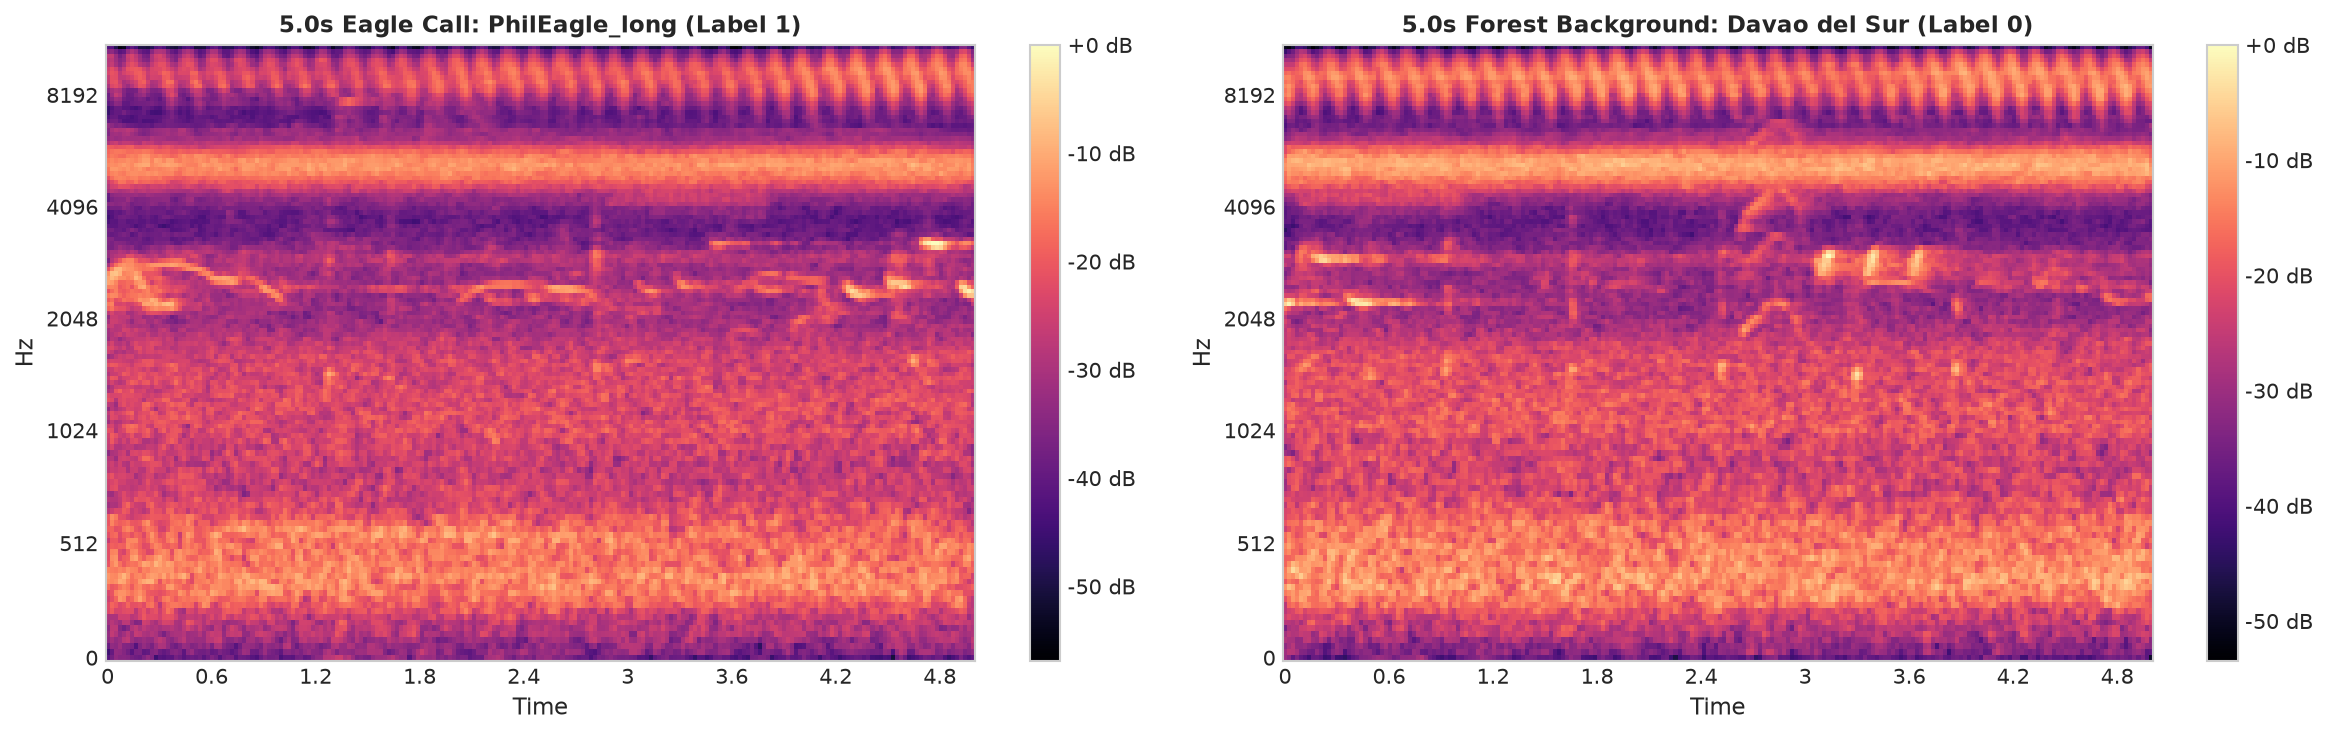

In [6]:
# Multi-panel visualization: 5s Mel Spectrogram samples (Eagle vs. Background)
sample_eagle_5s = df_clean_5s[df_clean_5s["label"] == 1].iloc[0]
sample_bg_5s = df_clean_5s[df_clean_5s["label"] == 0].iloc[0]

y_eagle_5s, _ = librosa.load(AUDIO_5S_DIR / sample_eagle_5s["file_name"], sr=TARGET_SR)
y_bg_5s, _ = librosa.load(AUDIO_5S_DIR / sample_bg_5s["file_name"], sr=TARGET_SR)

mel_eagle_5s = extract_log_mel_spectrogram(y_eagle_5s, TARGET_SR)
mel_bg_5s = extract_log_mel_spectrogram(y_bg_5s, TARGET_SR)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

img1 = librosa.display.specshow(
    mel_eagle_5s, sr=TARGET_SR, hop_length=HOP_LENGTH,
    x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
    ax=axes[0], cmap="magma"
)
axes[0].set_title(f"5.0s Eagle Call: {sample_eagle_5s['call_types']} (Label 1)", fontsize=11, fontweight="bold")
fig.colorbar(img1, ax=axes[0], format="%+2.0f dB")

img2 = librosa.display.specshow(
    mel_bg_5s, sr=TARGET_SR, hop_length=HOP_LENGTH,
    x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
    ax=axes[1], cmap="magma"
)
axes[1].set_title(f"5.0s Forest Background: {sample_bg_5s['site']} (Label 0)", fontsize=11, fontweight="bold")
fig.colorbar(img2, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
fig_path = SPECTROGRAMS_DIR / f"{NOTEBOOK_ID}-5s-melSpectrogram-samples.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()

### 4.3. Extract and Save 5.0-Second PCEN Mel Spectrograms

In [7]:
# Extract and save 5.0s PCEN Mel Spectrograms
pcen_5s_dir = FEATURES_5S_DIR / "pcen-melSpectrogram"
df_pcen_5s_meta, pcen_5s_dir = save_feature_dataset(
    feature_name="pcen-melSpectrogram",
    extract_func=extract_pcen_mel_spectrogram,
    df_dataset=df_clean_5s,
    audio_dir=AUDIO_5S_DIR,
    output_dir=pcen_5s_dir
)

Directory '/home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/pcen-melSpectrogram' is already populated (6289 files found).
Loading existing features metadata from: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/pcen-melSpectrogram/features_metadata.csv


### 4.4. Visual Comparison: 5.0-Second PCEN Mel Spectrograms (Eagle vs. Background)

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/spectrograms/03-feature-extraction-5s-pcen-melSpectrogram-samples.png


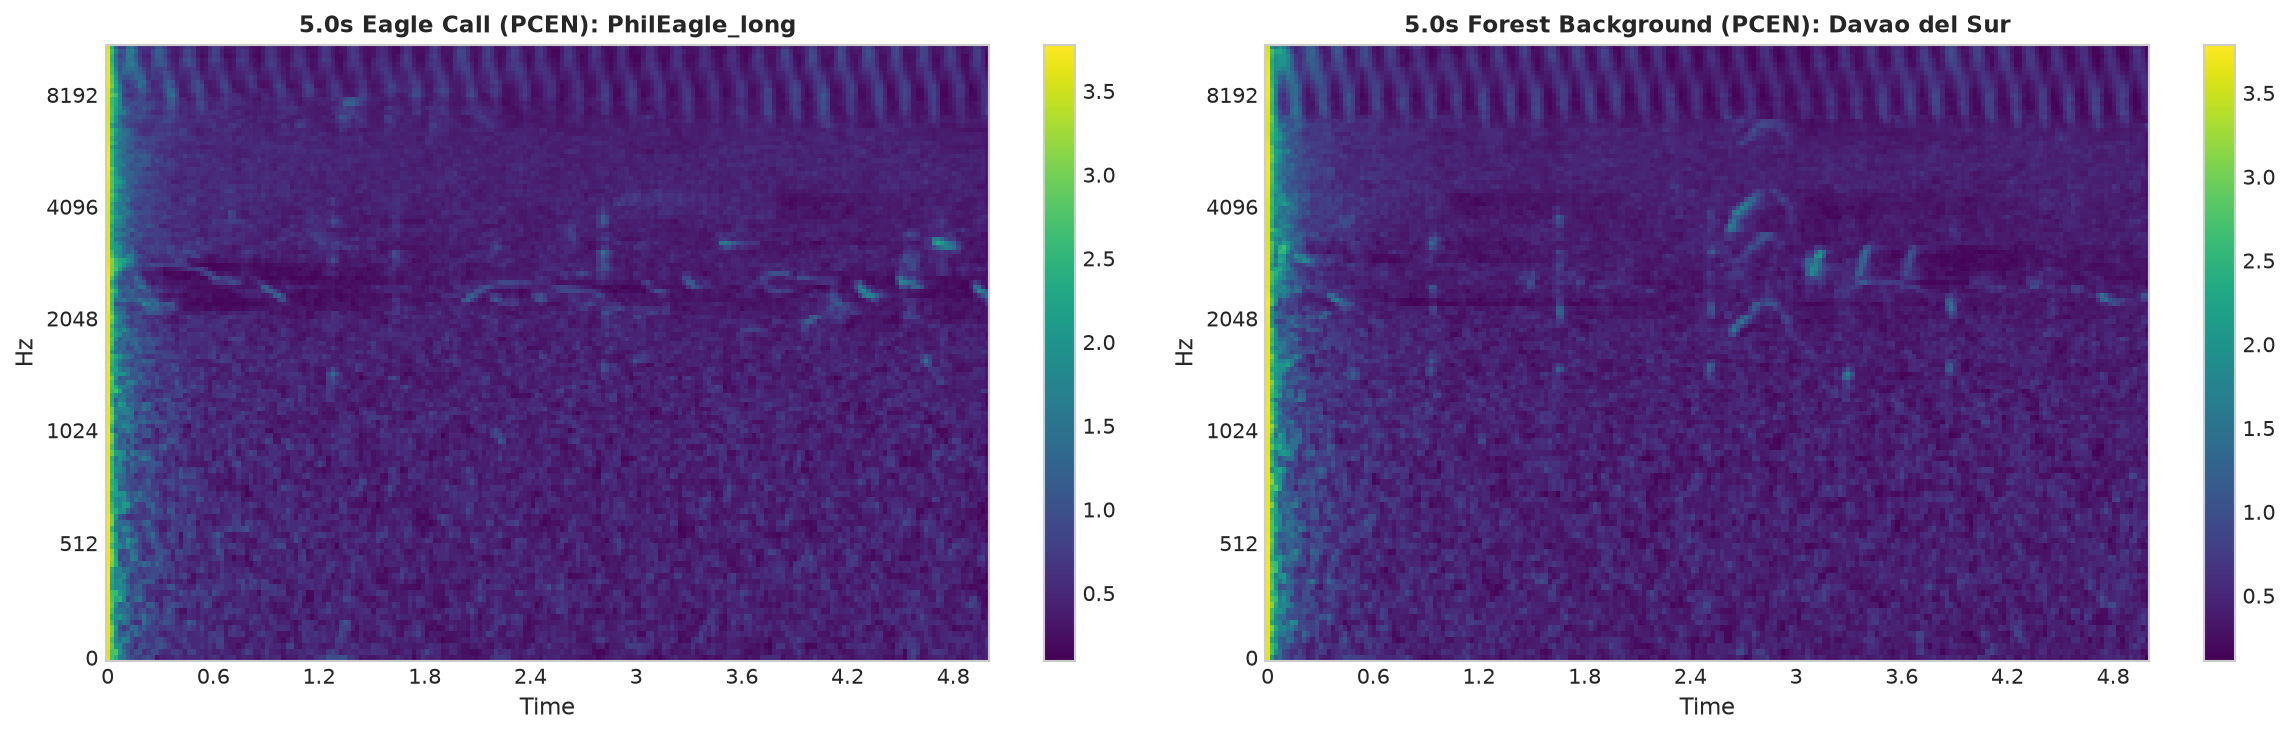

In [8]:
# Multi-panel visualization: 5s PCEN Mel Spectrogram samples (Eagle vs. Background)
pcen_eagle_5s = extract_pcen_mel_spectrogram(y_eagle_5s, TARGET_SR)
pcen_bg_5s = extract_pcen_mel_spectrogram(y_bg_5s, TARGET_SR)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

img1 = librosa.display.specshow(
    pcen_eagle_5s, sr=TARGET_SR, hop_length=HOP_LENGTH,
    x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
    ax=axes[0], cmap="viridis"
)
axes[0].set_title(f"5.0s Eagle Call (PCEN): {sample_eagle_5s['call_types']}", fontsize=11, fontweight="bold")
fig.colorbar(img1, ax=axes[0])

img2 = librosa.display.specshow(
    pcen_bg_5s, sr=TARGET_SR, hop_length=HOP_LENGTH,
    x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
    ax=axes[1], cmap="viridis"
)
axes[1].set_title(f"5.0s Forest Background (PCEN): {sample_bg_5s['site']}", fontsize=11, fontweight="bold")
fig.colorbar(img2, ax=axes[1])

plt.tight_layout()
fig_path = SPECTROGRAMS_DIR / f"{NOTEBOOK_ID}-5s-pcen-melSpectrogram-samples.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()

### 4.5. Summary and Verification of 5.0-Second Feature Arrays

In [9]:
# Verify 5.0s feature arrays
sample_5s_file = list(pcen_5s_dir.glob("*.npy"))[0]
sample_5s_arr = np.load(sample_5s_file)

print("=" * 60)
print("5.0-SECOND FEATURE ARRAYS SUMMARY & VERIFICATION")
print("=" * 60)
print(f"Mel Spectrogram Dir:        {mel_5s_dir}")
print(f"PCEN Spectrogram Dir:       {pcen_5s_dir}")
print(f"Total .npy Files:           {len(list(pcen_5s_dir.glob('*.npy')))}")
print(f"Sample File Name:           {sample_5s_file.name}")
print(f"Array Shape (mels, frames): {sample_5s_arr.shape}")
print(f"Array Data Type:            {sample_5s_arr.dtype}")
print(f"Value Range:                [{sample_5s_arr.min():.2f}, {sample_5s_arr.max():.2f}]")
print(f"Metadata Records:           {len(df_pcen_5s_meta)}")
print("=" * 60)

5.0-SECOND FEATURE ARRAYS SUMMARY & VERIFICATION
Mel Spectrogram Dir:        /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/melSpectrogram
PCEN Spectrogram Dir:       /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/5-seconds/pcen-melSpectrogram
Total .npy Files:           6289
Sample File Name:           converted_179796_01028.0_01033.0.npy
Array Shape (mels, frames): (128, 216)
Array Data Type:            float32
Value Range:                [0.06, 3.76]
Metadata Records:           6289


## 5. Feature Extraction: 3.0-Second Windows

### 5.1. Extract and Save 3.0-Second Mel Spectrograms

In [10]:
# Extract and save 3.0s Log-Mel Spectrograms
mel_3s_dir = FEATURES_3S_DIR / "melSpectrogram"
df_mel_3s_meta, mel_3s_dir = save_feature_dataset(
    feature_name="melSpectrogram",
    extract_func=extract_log_mel_spectrogram,
    df_dataset=df_clean_3s,
    audio_dir=AUDIO_3S_DIR,
    output_dir=mel_3s_dir
)

Extracting 'melSpectrogram' for 8599 clips...


Extracting melSpectrogram: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8599/8599 [02:00<00:00, 71.16it/s]



Saved 8599 feature arrays to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/melSpectrogram
Saved feature metadata to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/melSpectrogram/features_metadata.csv


### 5.2. Visual Comparison: 3.0-Second Mel Spectrograms (Eagle vs. Background)

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/spectrograms/03-feature-extraction-3s-melSpectrogram-samples.png


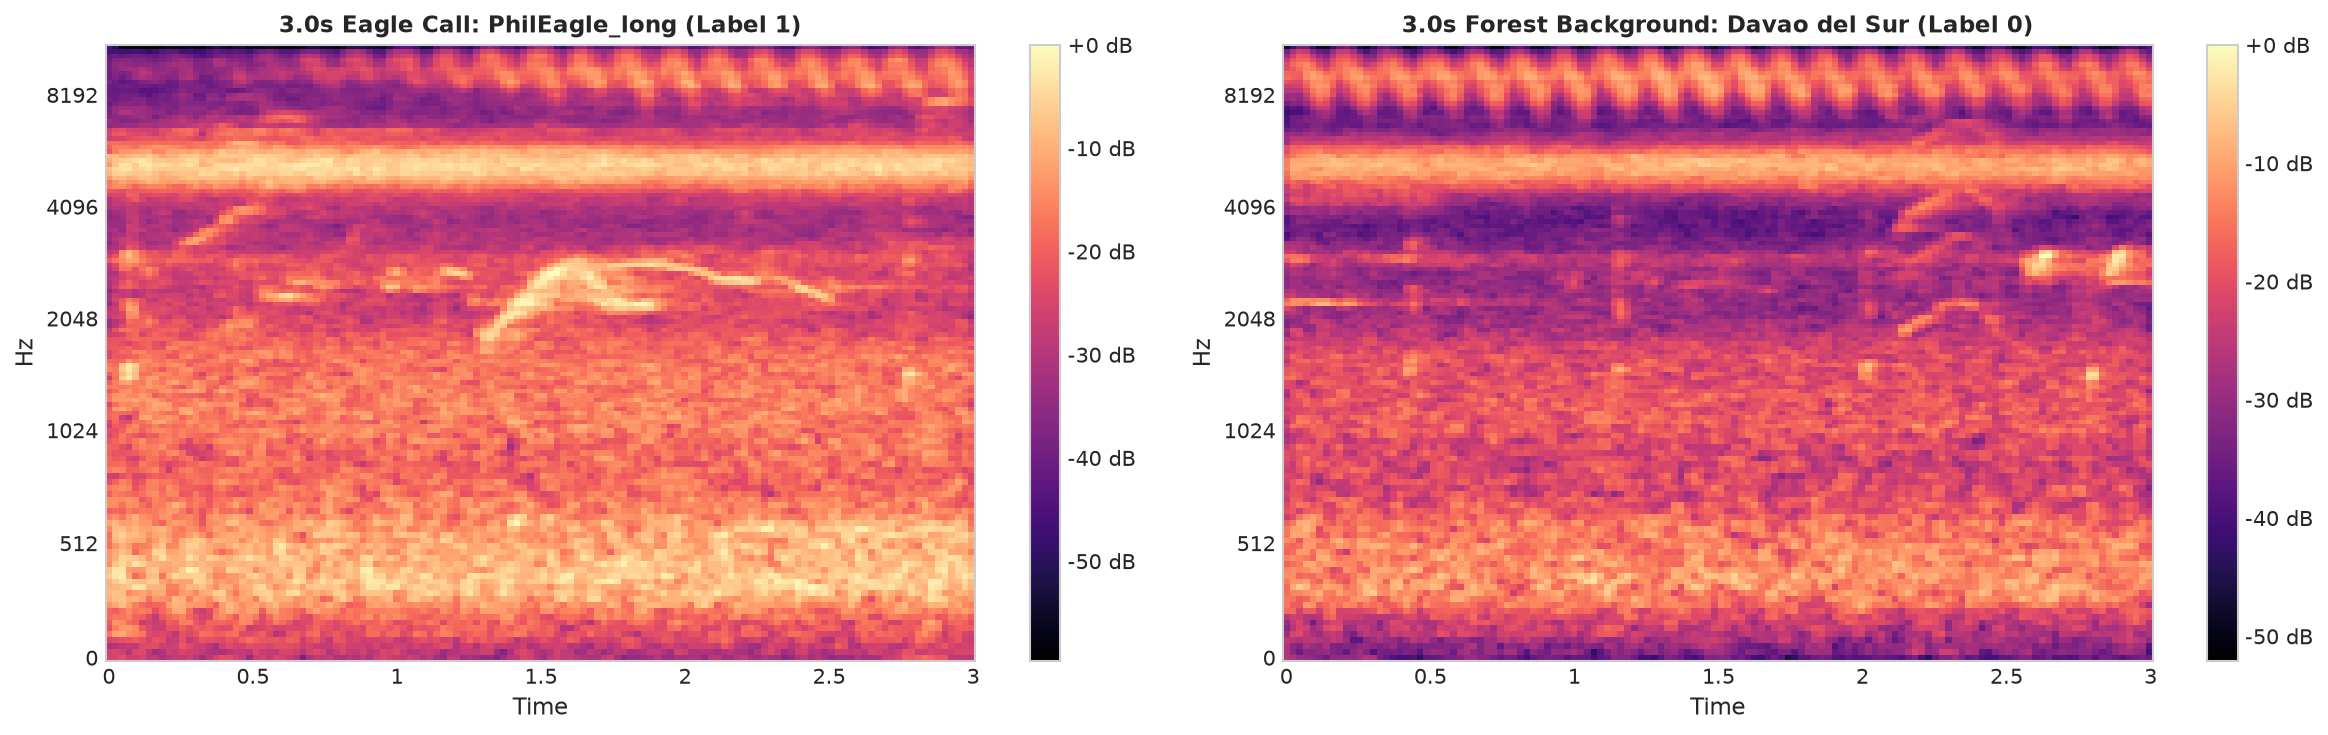

In [11]:
# Multi-panel visualization: 3s Mel Spectrogram samples (Eagle vs. Background)
if len(df_clean_3s) > 0:
    sample_eagle_3s = df_clean_3s[df_clean_3s["label"] == 1].iloc[0]
    sample_bg_3s = df_clean_3s[df_clean_3s["label"] == 0].iloc[0]

    y_eagle_3s, _ = librosa.load(AUDIO_3S_DIR / sample_eagle_3s["file_name"], sr=TARGET_SR)
    y_bg_3s, _ = librosa.load(AUDIO_3S_DIR / sample_bg_3s["file_name"], sr=TARGET_SR)

    mel_eagle_3s = extract_log_mel_spectrogram(y_eagle_3s, TARGET_SR)
    mel_bg_3s = extract_log_mel_spectrogram(y_bg_3s, TARGET_SR)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    img1 = librosa.display.specshow(
        mel_eagle_3s, sr=TARGET_SR, hop_length=HOP_LENGTH,
        x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
        ax=axes[0], cmap="magma"
    )
    axes[0].set_title(f"3.0s Eagle Call: {sample_eagle_3s['call_types']} (Label 1)", fontsize=11, fontweight="bold")
    fig.colorbar(img1, ax=axes[0], format="%+2.0f dB")

    img2 = librosa.display.specshow(
        mel_bg_3s, sr=TARGET_SR, hop_length=HOP_LENGTH,
        x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
        ax=axes[1], cmap="magma"
    )
    axes[1].set_title(f"3.0s Forest Background: {sample_bg_3s['site']} (Label 0)", fontsize=11, fontweight="bold")
    fig.colorbar(img2, ax=axes[1], format="%+2.0f dB")

    plt.tight_layout()
    fig_path = SPECTROGRAMS_DIR / f"{NOTEBOOK_ID}-3s-melSpectrogram-samples.png"
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    print(f"Saved figure: {fig_path}")
    plt.show()
else:
    print("Skipping 3.0s visualization (no 3s clips loaded).")

### 5.3. Extract and Save 3.0-Second PCEN Mel Spectrograms

In [12]:
# Extract and save 3.0s PCEN Mel Spectrograms
pcen_3s_dir = FEATURES_3S_DIR / "pcen-melSpectrogram"
df_pcen_3s_meta, pcen_3s_dir = save_feature_dataset(
    feature_name="pcen-melSpectrogram",
    extract_func=extract_pcen_mel_spectrogram,
    df_dataset=df_clean_3s,
    audio_dir=AUDIO_3S_DIR,
    output_dir=pcen_3s_dir
)

Extracting 'pcen-melSpectrogram' for 8599 clips...


Extracting pcen-melSpectrogram: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8599/8599 [01:55<00:00, 74.36it/s]



Saved 8599 feature arrays to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram
Saved feature metadata to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram/features_metadata.csv


### 5.4. Visual Comparison: 3.0-Second PCEN Mel Spectrograms (Eagle vs. Background)

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/spectrograms/03-feature-extraction-3s-pcen-melSpectrogram-samples.png


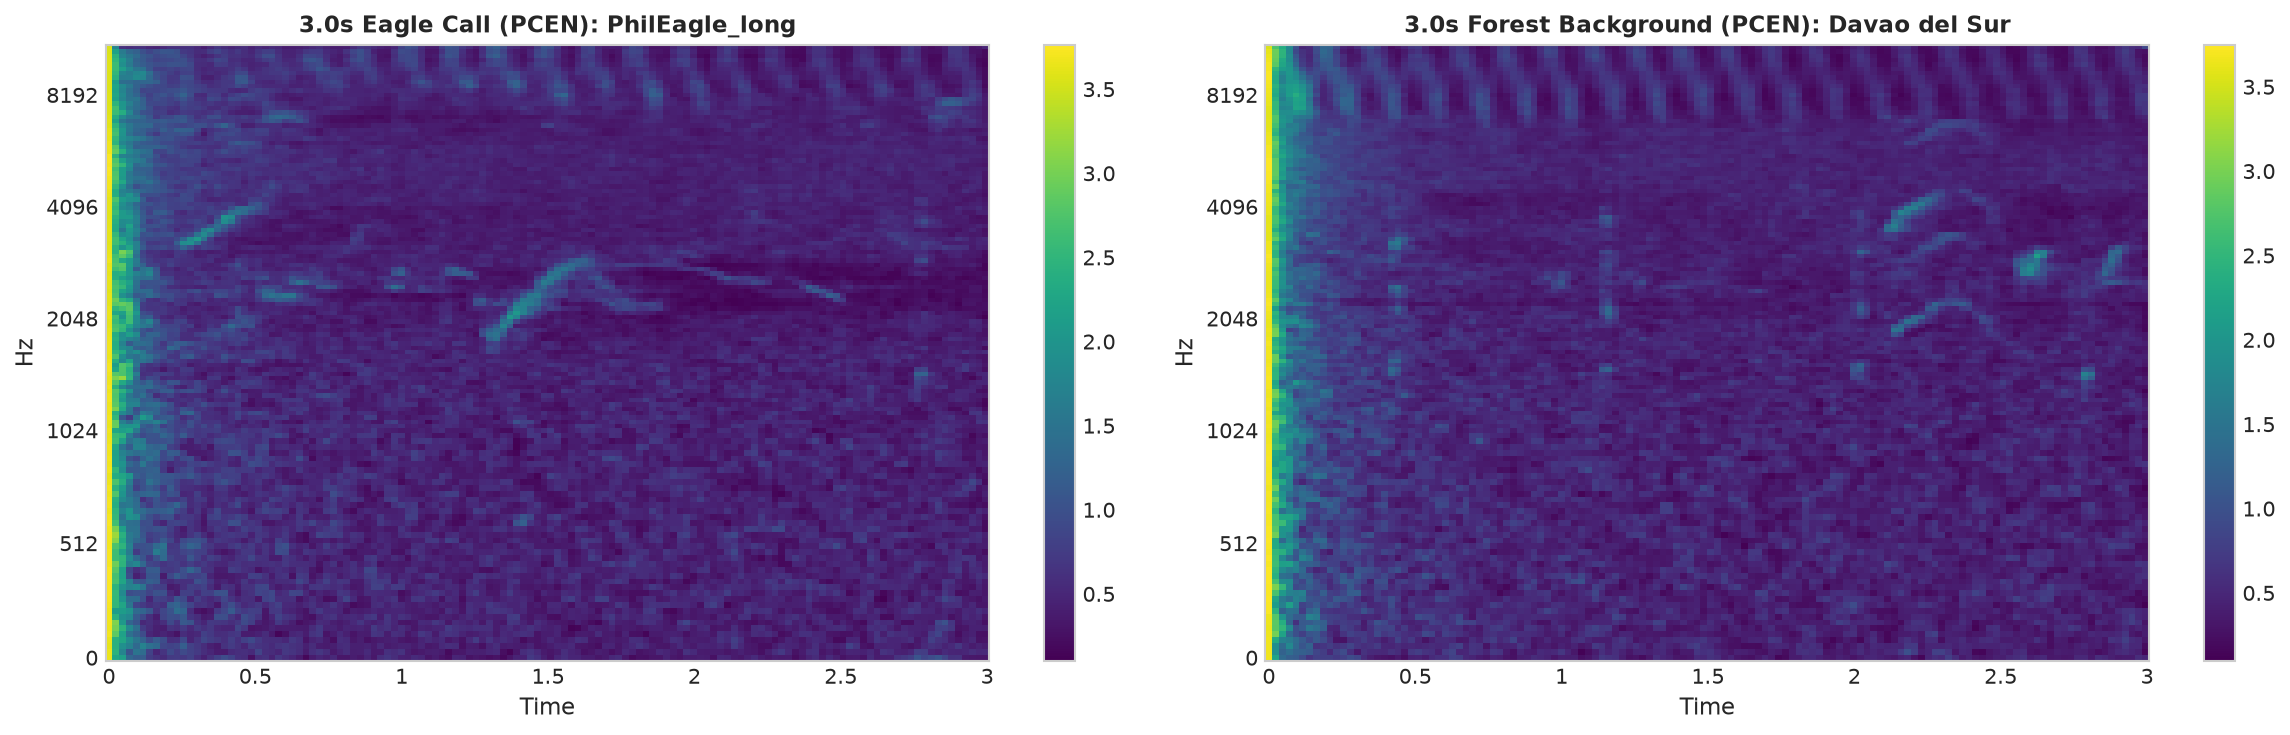

In [13]:
# Multi-panel visualization: 3s PCEN Mel Spectrogram samples (Eagle vs. Background)
if len(df_clean_3s) > 0:
    pcen_eagle_3s = extract_pcen_mel_spectrogram(y_eagle_3s, TARGET_SR)
    pcen_bg_3s = extract_pcen_mel_spectrogram(y_bg_3s, TARGET_SR)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    img1 = librosa.display.specshow(
        pcen_eagle_3s, sr=TARGET_SR, hop_length=HOP_LENGTH,
        x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
        ax=axes[0], cmap="viridis"
    )
    axes[0].set_title(f"3.0s Eagle Call (PCEN): {sample_eagle_3s['call_types']}", fontsize=11, fontweight="bold")
    fig.colorbar(img1, ax=axes[0])

    img2 = librosa.display.specshow(
        pcen_bg_3s, sr=TARGET_SR, hop_length=HOP_LENGTH,
        x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
        ax=axes[1], cmap="viridis"
    )
    axes[1].set_title(f"3.0s Forest Background (PCEN): {sample_bg_3s['site']}", fontsize=11, fontweight="bold")
    fig.colorbar(img2, ax=axes[1])

    plt.tight_layout()
    fig_path = SPECTROGRAMS_DIR / f"{NOTEBOOK_ID}-3s-pcen-melSpectrogram-samples.png"
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    print(f"Saved figure: {fig_path}")
    plt.show()
else:
    print("Skipping 3.0s PCEN visualization (no 3s clips loaded).")

### 5.5. Summary and Verification of 3.0-Second Feature Arrays

In [14]:
# Verify 3.0s feature arrays
if pcen_3s_dir.exists() and len(list(pcen_3s_dir.glob("*.npy"))) > 0:
    sample_3s_file = list(pcen_3s_dir.glob("*.npy"))[0]
    sample_3s_arr = np.load(sample_3s_file)

    print("=" * 60)
    print("3.0-SECOND FEATURE ARRAYS SUMMARY & VERIFICATION")
    print("=" * 60)
    print(f"Mel Spectrogram Dir:        {mel_3s_dir}")
    print(f"PCEN Spectrogram Dir:       {pcen_3s_dir}")
    print(f"Total .npy Files:           {len(list(pcen_3s_dir.glob('*.npy')))}")
    print(f"Sample File Name:           {sample_3s_file.name}")
    print(f"Array Shape (mels, frames): {sample_3s_arr.shape}")
    print(f"Array Data Type:            {sample_3s_arr.dtype}")
    print(f"Value Range:                [{sample_3s_arr.min():.2f}, {sample_3s_arr.max():.2f}]")
    print(f"Metadata Records:           {len(df_pcen_3s_meta)}")
    print("=" * 60)
else:
    print("No 3.0-second feature arrays found yet.")

3.0-SECOND FEATURE ARRAYS SUMMARY & VERIFICATION
Mel Spectrogram Dir:        /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/melSpectrogram
PCEN Spectrogram Dir:       /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/features/3-seconds/pcen-melSpectrogram
Total .npy Files:           8599
Sample File Name:           converted_183492_00025.5_00028.5.npy
Array Shape (mels, frames): (128, 130)
Array Data Type:            float32
Value Range:                [0.05, 3.83]
Metadata Records:           8599


## 6. Multi-Scale Comparison and Visualizations

### 6.1. Side-by-Side Spectrogram Dimension & Statistics Comparison

In [15]:
# Multi-scale feature comparison table
feat_comp_data = {
    "Feature Dimension / Attribute": [
        "Snippet Window Length",
        "Target Sample Rate",
        "FFT Size (n_fft)",
        "Hop Length",
        "Mel Frequency Bands",
        "Output Array Shape (Mels, Frames)",
        "Clean Clips Extracted",
        "Eagle Call Slices (1)",
        "Background Slices (0)",
        "Storage Directory"
    ],
    "5.0-Second Pipeline": [
        "5.0 seconds",
        f"{TARGET_SR} Hz",
        f"{N_FFT}",
        f"{HOP_LENGTH}",
        f"{N_MELS}",
        f"({N_MELS}, 216)",
        f"{len(df_clean_5s):,}",
        f"{(df_clean_5s['label'] == 1).sum():,}",
        f"{(df_clean_5s['label'] == 0).sum():,}",
        "data/features/5-seconds/"
    ],
    "3.0-Second Pipeline": [
        "3.0 seconds",
        f"{TARGET_SR} Hz",
        f"{N_FFT}",
        f"{HOP_LENGTH}",
        f"{N_MELS}",
        f"({N_MELS}, 130)",
        f"{len(df_clean_3s):,}" if len(df_clean_3s) > 0 else "N/A",
        f"{(df_clean_3s['label'] == 1).sum():,}" if len(df_clean_3s) > 0 else "N/A",
        f"{(df_clean_3s['label'] == 0).sum():,}" if len(df_clean_3s) > 0 else "N/A",
        "data/features/3-seconds/"
    ]
}

df_feat_comp = pd.DataFrame(feat_comp_data)
print("=" * 75)
print("MULTI-SCALE SPECTROGRAM FEATURE EXTRACTION COMPARISON")
print("=" * 75)
print(df_feat_comp.to_string(index=False))
print("=" * 75)

MULTI-SCALE SPECTROGRAM FEATURE EXTRACTION COMPARISON
    Feature Dimension / Attribute      5.0-Second Pipeline      3.0-Second Pipeline
            Snippet Window Length              5.0 seconds              3.0 seconds
               Target Sample Rate                 22050 Hz                 22050 Hz
                 FFT Size (n_fft)                     2048                     2048
                       Hop Length                      512                      512
              Mel Frequency Bands                      128                      128
Output Array Shape (Mels, Frames)               (128, 216)               (128, 130)
            Clean Clips Extracted                    6,289                    8,599
            Eagle Call Slices (1)                    2,851                    3,337
            Background Slices (0)                    3,438                    5,262
                Storage Directory data/features/5-seconds/ data/features/3-seconds/


### 6.2. Comparative Multi-Panel Spectrogram Visualization (5.0s vs. 3.0s)

Saved multi-scale comparison figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/spectrograms/03-feature-extraction-5s-vs-3s-spectrogram-comparison.png


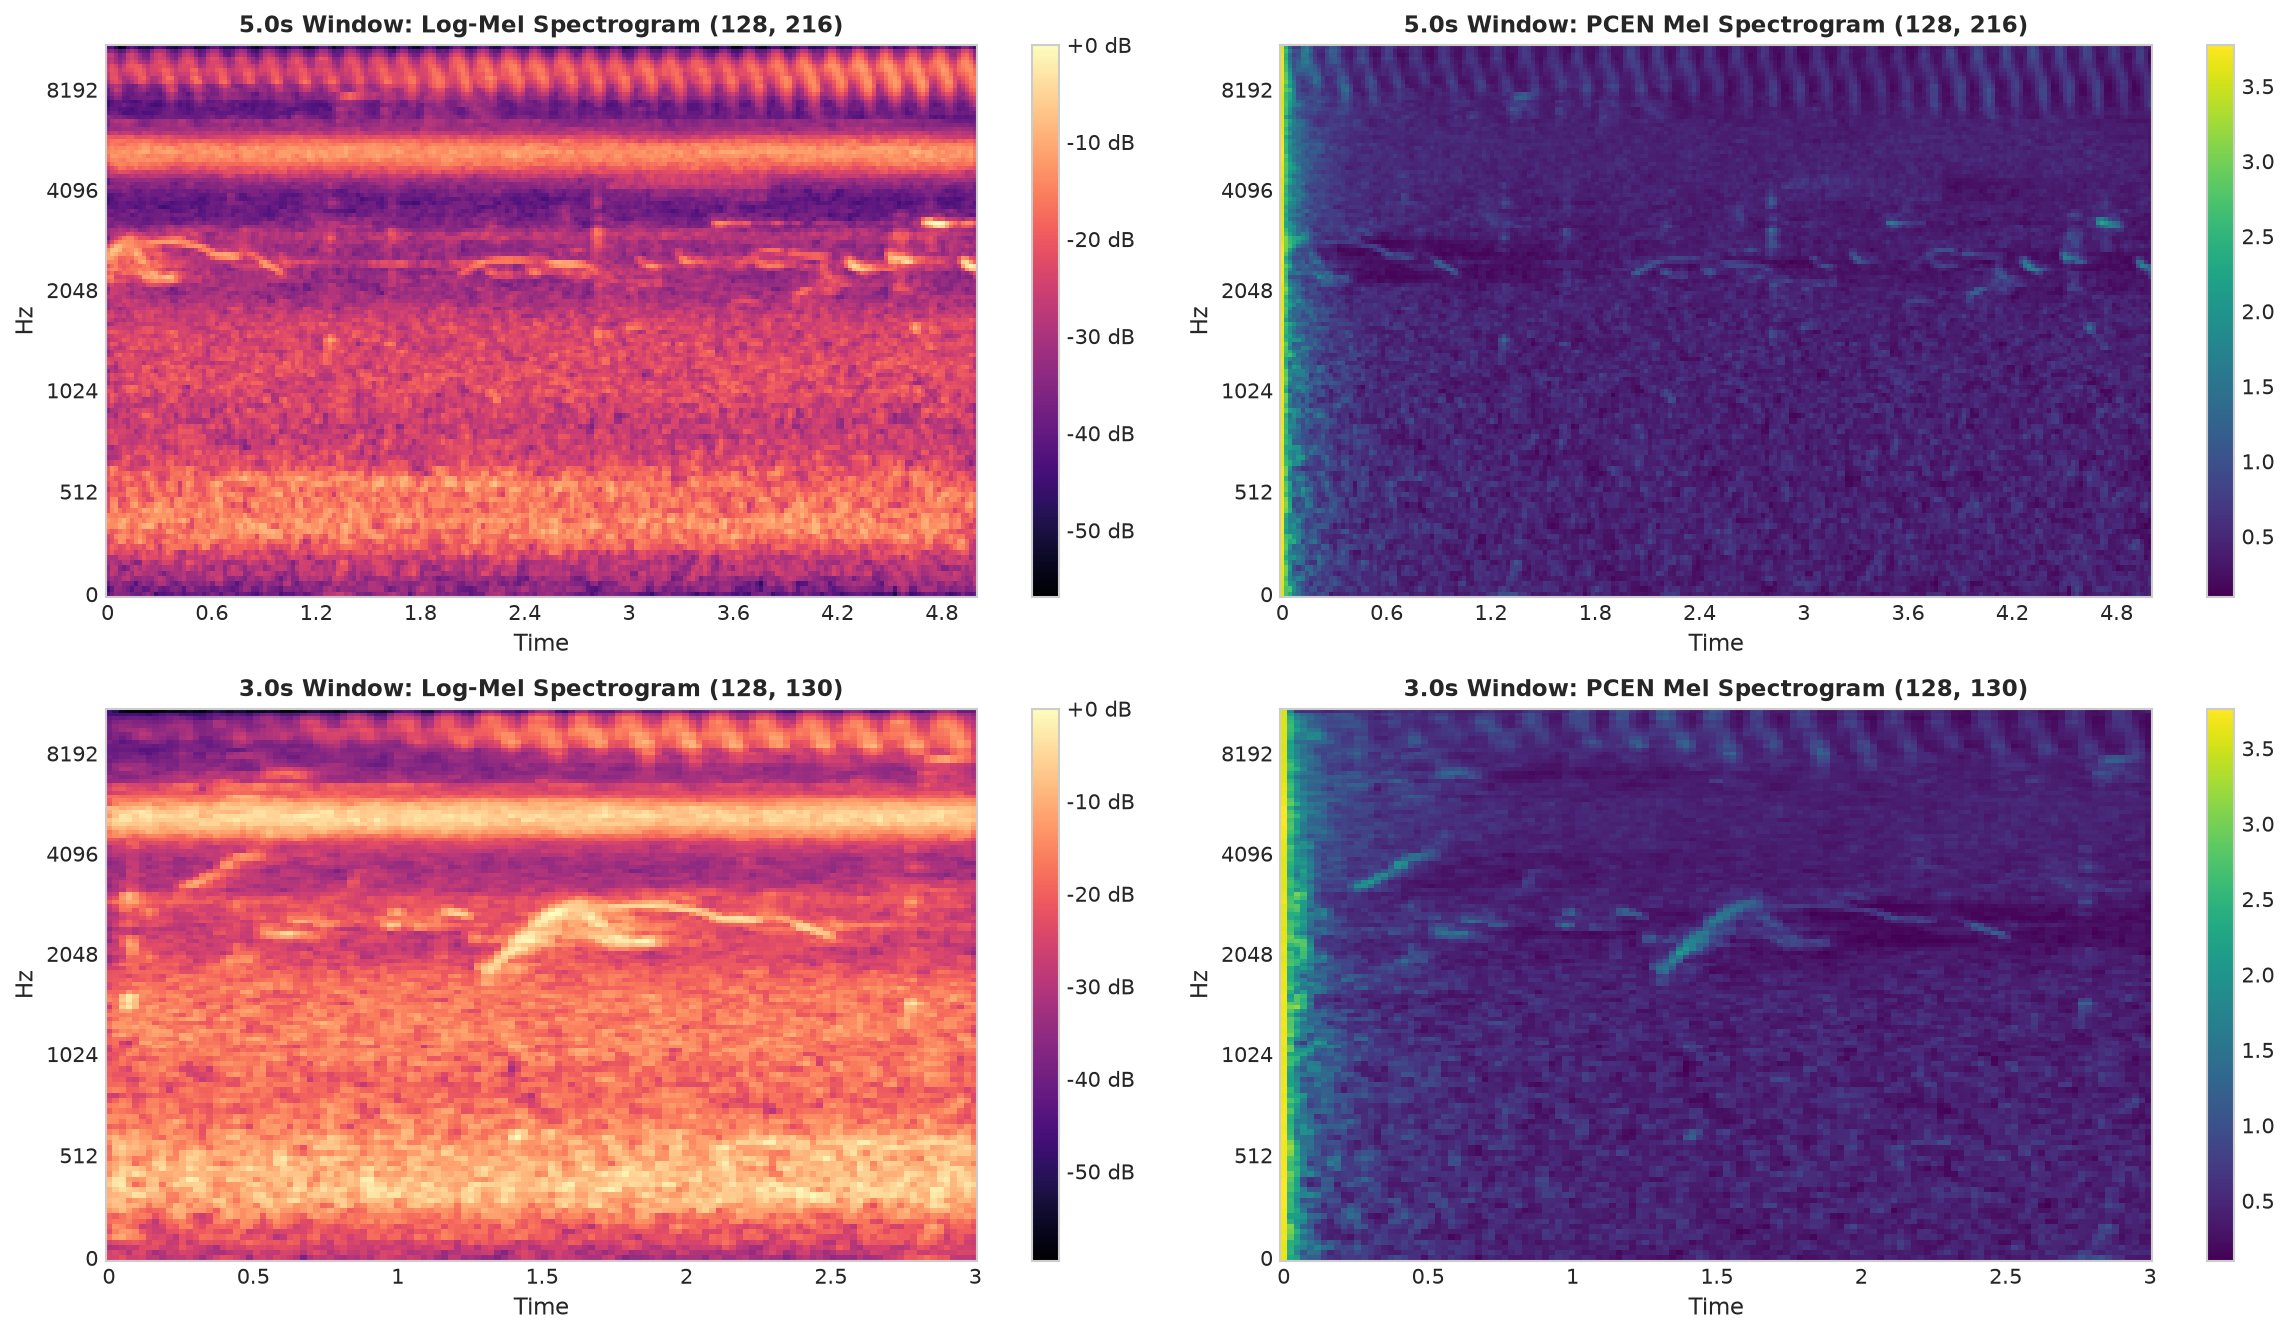

In [16]:
# Multi-panel visualization comparing 5s vs 3s Mel and PCEN spectrograms
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# Panel (0, 0): 5s Mel
img00 = librosa.display.specshow(
    mel_eagle_5s, sr=TARGET_SR, hop_length=HOP_LENGTH,
    x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
    ax=axes[0, 0], cmap="magma"
)
axes[0, 0].set_title(f"5.0s Window: Log-Mel Spectrogram {mel_eagle_5s.shape}", fontsize=11, fontweight="bold")
fig.colorbar(img00, ax=axes[0, 0], format="%+2.0f dB")

# Panel (0, 1): 5s PCEN
img01 = librosa.display.specshow(
    pcen_eagle_5s, sr=TARGET_SR, hop_length=HOP_LENGTH,
    x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
    ax=axes[0, 1], cmap="viridis"
)
axes[0, 1].set_title(f"5.0s Window: PCEN Mel Spectrogram {pcen_eagle_5s.shape}", fontsize=11, fontweight="bold")
fig.colorbar(img01, ax=axes[0, 1])

# Panels (1, 0) & (1, 1): 3s Mel and PCEN (if available)
if len(df_clean_3s) > 0:
    img10 = librosa.display.specshow(
        mel_eagle_3s, sr=TARGET_SR, hop_length=HOP_LENGTH,
        x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
        ax=axes[1, 0], cmap="magma"
    )
    axes[1, 0].set_title(f"3.0s Window: Log-Mel Spectrogram {mel_eagle_3s.shape}", fontsize=11, fontweight="bold")
    fig.colorbar(img10, ax=axes[1, 0], format="%+2.0f dB")

    img11 = librosa.display.specshow(
        pcen_eagle_3s, sr=TARGET_SR, hop_length=HOP_LENGTH,
        x_axis="time", y_axis="mel", fmin=FMIN, fmax=FMAX,
        ax=axes[1, 1], cmap="viridis"
    )
    axes[1, 1].set_title(f"3.0s Window: PCEN Mel Spectrogram {pcen_eagle_3s.shape}", fontsize=11, fontweight="bold")
    fig.colorbar(img11, ax=axes[1, 1])
else:
    axes[1, 0].text(0.5, 0.5, "3.0s Mel Spectrogram\n(Run 02-preprocess for 3s first)", ha="center", va="center")
    axes[1, 1].text(0.5, 0.5, "3.0s PCEN Mel Spectrogram\n(Run 02-preprocess for 3s first)", ha="center", va="center")

plt.tight_layout()
comp_fig_path = SPECTROGRAMS_DIR / f"{NOTEBOOK_ID}-5s-vs-3s-spectrogram-comparison.png"
fig.savefig(comp_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved multi-scale comparison figure: {comp_fig_path}")
plt.show()

### 6.3. Feature Extraction Pipeline Summary & Downstream Recommendations

In [17]:
# Summary and recommendations for model architectures
print("=" * 75)
print("FEATURE EXTRACTION PIPELINE SUMMARY & DOWNSTREAM MODEL RECOMMENDATIONS")
print("=" * 75)
print("1. 5.0-Second Representations (128, 216):")
print("   - Stored in data/features/5-seconds/pcen-melSpectrogram/")
print("   - Designed for CRNN-GRU and recurrent architectures with temporal modeling.")
print("2. 3.0-Second Representations (128, 130):")
print("   - Stored in data/features/3-seconds/pcen-melSpectrogram/")
print("   - Standard window length for bioacoustic transfer learning (e.g. BirdNET, BAD).")
print("3. PCEN vs. Log-Mel:")
print("   - PCEN dynamically suppresses steady tropical rainforest noise (rain, insect choruses).")
print("   - Retains sharp transient attack of Philippine eagle high-pitched whistles.")
print("=" * 75)

FEATURE EXTRACTION PIPELINE SUMMARY & DOWNSTREAM MODEL RECOMMENDATIONS
1. 5.0-Second Representations (128, 216):
   - Stored in data/features/5-seconds/pcen-melSpectrogram/
   - Designed for CRNN-GRU and recurrent architectures with temporal modeling.
2. 3.0-Second Representations (128, 130):
   - Stored in data/features/3-seconds/pcen-melSpectrogram/
   - Standard window length for bioacoustic transfer learning (e.g. BirdNET, BAD).
3. PCEN vs. Log-Mel:
   - PCEN dynamically suppresses steady tropical rainforest noise (rain, insect choruses).
   - Retains sharp transient attack of Philippine eagle high-pitched whistles.
